# Federated Random Forest — Give Me Some Credit

Notebook thực nghiệm local theo **Protocol v1.0**: 60% train, 20% validation, 20% test; 5 client × 20 cây, một vòng ghép rừng. Centralized 100 cây dùng cùng train, validation, test và tham số. Đây là mô phỏng local; việc chạy SuperLink/SuperNode trên Azure cần thực hiện riêng. Không có dữ liệu bản ghi train được chuyển cho hàm aggregation trong luồng thí nghiệm này; bước chuẩn bị dữ liệu vẫn tập trung.

Chạy từ thư mục repository bằng **Run All**. Đặt `SOURCE_CSV` và `PROJECT_ROOT` nếu môi trường khác. Cần `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `nbformat` và mã trong `flower-app/fl_app`.

**Nguồn số liệu FL triển khai:** kết quả Flower chạy trên Azure là `results/azure_traffic_new_run/flower_seed42_iid_clients5.json` (run `2172526506691903996`). Không cần Run All notebook local để có lại metric cloud; các ô huấn luyện local chỉ giải thích và kiểm chứng cách ghép cây.


## 1. Cấu hình và giao thức

In [1]:
from pathlib import Path
import json, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, precision_recall_curve)

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "flower-app" / "fl_app").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SOURCE_CSV = PROJECT_ROOT / "data" / "cs-training.csv"
DATA_ROOT = PROJECT_ROOT / "data" / "experiments"
RESULT_ROOT = PROJECT_ROOT / "results" / "protocol_v1"
SEED = 42
N_CLIENTS = 5
TREES_PER_CLIENT = 20
MODE = "iid"  # "non-iid" là phép thử riêng; dùng ALPHA khi chọn chế độ này.
ALPHA = 0.5
MIN_RECALL = 0.30
RF_CONFIG = dict(max_depth=10, min_samples_leaf=5, max_features="sqrt", class_weight=None)
sys.path.insert(0, str(PROJECT_ROOT / "flower-app"))
from fl_app.protocol import (TARGET, ROW_ID, prepare_split, prepare_external_inference, partition_train, read_checked,
                             sha256)
from fl_app.tree_codec import encode_forest, decode_forests, schema_hash
print("Source:", SOURCE_CSV)
print("RF:", RF_CONFIG)

Source: C:\Users\ACER\Documents\ChatGPT\Project Cloud\data\cs-training.csv
RF: {'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': None}


## 2. Tạo split và phân vùng Client

Median chỉ học từ Train 90.000 dòng. Giữ nội dung trùng nhưng source row ID không được trùng giữa các tập. Các file/manifest là đầu vào có thể cấp riêng cho từng VM; không đưa Validation/Test cho Client.

In [ ]:
split_dir = prepare_split(SOURCE_CSV, DATA_ROOT, SEED)
external_source = PROJECT_ROOT / "data" / "cs-test.csv"
if external_source.is_file():
    external_path = prepare_external_inference(external_source, split_dir)
    print("Unlabeled external inference:", external_path)
partition_dir = partition_train(split_dir, MODE, ALPHA, N_CLIENTS, SEED)
schema = json.loads((split_dir / "feature_schema.json").read_text(encoding="utf-8"))
manifest = json.loads((split_dir / "split_metadata.json").read_text(encoding="utf-8"))
partition_summary = json.loads((partition_dir / "summary.json").read_text(encoding="utf-8"))
train = read_checked(split_dir / "train.csv", schema)
validation = read_checked(split_dir / "validation.csv", schema)
test = read_checked(split_dir / "test.csv", schema)
clients = [read_checked(partition_dir / f"client_{i}.csv", schema) for i in range(1, N_CLIENTS + 1)]
assert sum(len(frame) for frame in clients) == len(train)
assert set().union(*(set(frame[ROW_ID]) for frame in clients)) == set(train[ROW_ID])
assert all(set(clients[i][ROW_ID]).isdisjoint(clients[j][ROW_ID])
           for i in range(N_CLIENTS) for j in range(i + 1, N_CLIENTS))
assert set(train[ROW_ID]).isdisjoint(validation[ROW_ID])
assert set(train[ROW_ID]).isdisjoint(test[ROW_ID])
assert set(validation[ROW_ID]).isdisjoint(test[ROW_ID])
assert manifest["source_sha256"] == sha256(SOURCE_CSV)
assert all(manifest["split_sha256"][name] == sha256(split_dir / f"{name}.csv")
           for name in ("train", "validation", "test"))
assert all(item["sha256"] == sha256(partition_dir / f"client_{item['client_id']}.csv")
           for item in partition_summary["clients"])
display(pd.DataFrame({"split": ["train", "validation", "test"],
                      "rows": [len(train), len(validation), len(test)],
                      "positive_rate": [frame[TARGET].mean() for frame in (train, validation, test)]}))
display(pd.DataFrame(partition_summary["clients"]))
print("source_sha256:", manifest["source_sha256"])
print("feature_schema_sha256:", manifest["feature_schema_sha256"])
print("split_dir:", split_dir)

## 3. Fine tuning trên Train, tách khỏi phép so sánh đã đăng ký

Grid Search dùng **chỉ 90.000 hàng Train** và 3-fold stratified CV. Pipeline fit median **riêng trong từng training fold** trước khi đánh giá Average Precision (AP) trên fold còn lại. Validation/Test không tham gia chọn cấu hình ở đây. Bảng và hình bên dưới cho thấy tác động của độ sâu, kích thước nút lá và class weight.

**Quan trọng:** đây là phân tích tham số. Baseline Centralized và 5 Client ở các cell tiếp theo vẫn dùng `RF_CONFIG` đã khóa để so sánh công bằng với run Azure hiện có. Nếu muốn thay cấu hình theo kết quả tuning, phải cập nhật cả Centralized và Flower ClientApp, tạo run mới và không ghép với JSON Azure cũ.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from fl_app.protocol import load_source

# Lấy đúng các source_row_id thuộc Train; nguồn này còn giá trị thiếu.
raw_for_tuning, raw_features = load_source(SOURCE_CSV)
assert raw_features == schema["features"]
tuning_features = schema["features"]
raw_train = raw_for_tuning.set_index(ROW_ID).loc[train[ROW_ID], tuning_features]
assert np.array_equal(raw_for_tuning.set_index(ROW_ID).loc[train[ROW_ID], TARGET].to_numpy(),
                      train[TARGET].to_numpy())
assert len(raw_train) == len(train)

tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(
        n_estimators=N_CLIENTS * TREES_PER_CLIENT,
        max_features=RF_CONFIG["max_features"],
        random_state=SEED,
        n_jobs=1,
    )),
])
tuning_grid = {
    "rf__max_depth": [8, 10, 12],
    "rf__min_samples_leaf": [2, 5],
    "rf__class_weight": [None, "balanced_subsample"],
}
tuning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
tuning_search = GridSearchCV(
    tuning_pipeline, tuning_grid, scoring="average_precision",
    cv=tuning_cv, n_jobs=1, refit=False, return_train_score=False,
    error_score="raise",
)
tuning_search.fit(raw_train, train[TARGET])
tuning_table = pd.DataFrame(tuning_search.cv_results_)
tuning_table["is_protocol_config"] = tuning_table["params"].map(
    lambda p: p["rf__max_depth"] == RF_CONFIG["max_depth"]
    and p["rf__min_samples_leaf"] == RF_CONFIG["min_samples_leaf"]
    and p["rf__class_weight"] == RF_CONFIG["class_weight"]
)
assert tuning_table["is_protocol_config"].sum() == 1
tuning_table = tuning_table.sort_values("rank_test_score").reset_index(drop=True)
display(tuning_table[[
    "rank_test_score", "mean_test_score", "std_test_score",
    "param_rf__max_depth", "param_rf__min_samples_leaf",
    "param_rf__class_weight", "is_protocol_config"
]].rename(columns={
    "rank_test_score": "Hạng", "mean_test_score": "CV AP trung bình",
    "std_test_score": "CV AP độ lệch chuẩn",
    "is_protocol_config": "Giao thức Azure hiện tại",
}).round(4))
protocol_cv_ap = float(tuning_table.loc[tuning_table["is_protocol_config"], "mean_test_score"].iloc[0])
print("CV AP tốt nhất:", round(float(tuning_search.best_score_), 4), tuning_search.best_params_)
print("CV AP cấu hình giao thức:", round(protocol_cv_ap, 4))

top = tuning_table.head(8).iloc[::-1]
labels = [
    f"depth={p['rf__max_depth']} · leaf={p['rf__min_samples_leaf']} · weight={p['rf__class_weight'] or 'none'}"
    for p in top["params"]
]
colors = ["#2479b5" if current else "#8ca3b8" for current in top["is_protocol_config"]]
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(labels, top["mean_test_score"], xerr=top["std_test_score"],
        color=colors, capsize=3)
ax.set(xlabel="Average Precision (3-fold CV, Train 90.000 hàng)",
       title="Ảnh hưởng của tham số Random Forest trên Train")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

## 4. Huấn luyện Centralized và Client

Centralized dùng 100 cây trên cùng Train. Mỗi Client chỉ đọc partition của mình và fit 20 cây. Random seed từng Client khác nhau nhưng cấu hình RF như nhau.

In [ ]:
features = schema["features"]
start = time.perf_counter()
central = RandomForestClassifier(n_estimators=N_CLIENTS * TREES_PER_CLIENT,
                                 random_state=SEED, n_jobs=-1, **RF_CONFIG)
central.fit(train[features], train[TARGET])
central_seconds = time.perf_counter() - start
payloads, client_log = [], []
for client_id, frame in enumerate(clients, 1):
    start = time.perf_counter()
    model = RandomForestClassifier(n_estimators=TREES_PER_CLIENT,
                                   random_state=SEED + client_id, n_jobs=-1, **RF_CONFIG)
    model.fit(frame[features], frame[TARGET])
    payload = encode_forest(model)
    recovered = decode_forests([payload], features)
    sample = validation[features].iloc[:50]
    assert np.allclose(model.predict_proba(sample), recovered.predict_proba(sample.to_numpy()), atol=1e-10)
    payloads.append(payload)
    client_log.append({"client_id": client_id, "rows": len(frame),
                       "positive_rate": float(frame[TARGET].mean()),
                       "train_seconds": time.perf_counter() - start,
                       "numeric_payload_bytes": sum(array.nbytes for array in payload.values()),
                       "trees": len(model.estimators_)})
display(pd.DataFrame(client_log))
print("Centralized train seconds:", round(central_seconds, 2))

## 5. Ghép cây và kiểm tra payload

Aggregation chỉ nhận numeric tree payload; không nhận DataFrame/CSV của Client. Tổng cây là 100. Numeric payload bytes là kích thước mảng, **chưa phải byte mạng thực đo**. Model artifact vẫn có nguy cơ rò rỉ thông tin; đây không phải differential privacy.

In [ ]:
assert all(len(payload) == TREES_PER_CLIENT * 5 for payload in payloads)
forest = decode_forests(payloads, features)
assert len(forest.trees) == N_CLIENTS * TREES_PER_CLIENT
probe = validation[features].iloc[:25]
for payload, frame in zip(payloads, clients):
    assert len(payload) == TREES_PER_CLIENT * 5
for scores in (central.predict_proba(probe)[:, 1], forest.predict_proba(probe.to_numpy())[:, 1]):
    assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
payload_bytes = sum(row["numeric_payload_bytes"] for row in client_log)
print("Global trees:", len(forest.trees), "numeric payload bytes:", payload_bytes)
print("Schema hash used in Flower messages:", schema_hash(features))

## 6. Chọn ngưỡng trên Validation

Mỗi mô hình chọn ngưỡng F1 trên cùng validation; thêm ngưỡng ưu tiên precision với recall ít nhất 30%. Không dùng Test để chọn tham số hoặc ngưỡng.

In [ ]:
from fl_app.evaluation import choose_thresholds, evaluate

models = {"centralized": central, "federated": forest}
def probabilities(model, frame):
    values = frame[features] if model is central else frame[features].to_numpy()
    return model.predict_proba(values)[:, 1]

thresholds = {}
validation_rows = []
for name, model in models.items():
    scores = probabilities(model, validation)
    thresholds[name] = choose_thresholds(validation[TARGET].to_numpy(), scores, MIN_RECALL)
    for policy, threshold in thresholds[name].items():
        validation_rows.append({"model": name, "policy": policy,
                                **evaluate(validation[TARGET].to_numpy(), scores, threshold)})
display(pd.DataFrame(validation_rows).round(4))


## 7. Đánh giá cuối trên Test chung

In [ ]:
test_rows = []
test_inference_seconds = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, model in models.items():
    start = time.perf_counter()
    scores = probabilities(model, test)
    test_inference_seconds[name] = time.perf_counter() - start
    precision, recall, _ = precision_recall_curve(test[TARGET], scores)
    ap = average_precision_score(test[TARGET], scores)
    axes[0].plot(recall, precision, label=f"{name}: AP={ap:.3f}")
    for policy, threshold in thresholds[name].items():
        test_rows.append({"model": name, "policy": policy,
                          **evaluate(test[TARGET].to_numpy(), scores, threshold)})
results = pd.DataFrame(test_rows)
display(results.round(4))
axes[0].axhline(test[TARGET].mean(), linestyle="--", color="gray", label="Positive prevalence")
axes[0].set(title="Precision–Recall on shared Test", xlabel="Recall", ylabel="Precision", xlim=(0,1), ylim=(0,1))
axes[0].legend()
view = results[results.policy == "best_f1"].set_index("model")
view[["average_precision", "roc_auc", "f1", "precision", "recall"]].T.plot.bar(ax=axes[1])
axes[1].set(title="Centralized vs Federated — Test", ylabel="Score", ylim=(0,1))
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


## 8. Lưu kết quả và giới hạn

Lưu manifest và metrics có thể kiểm chứng. Không coi numeric payload bytes là băng thông mạng; Azure/Flower deployment phải đo truyền thực tế, thời gian và lưu run ID riêng. FL ở đây ghép cây, không dùng FedAvg. Đây là mô phỏng từ một dataset tập trung, không chứng minh bảo mật tuyệt đối. Test có thể đã được dùng trong thí nghiệm cũ; cần tập độc lập để ước lượng hiệu năng triển khai.

In [ ]:
run_id = f"seed{SEED}_{MODE}_clients{N_CLIENTS}_trees{TREES_PER_CLIENT}"
run_dir = RESULT_ROOT / run_id
run_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(run_dir / "test_metrics.csv", index=False)
pd.DataFrame(validation_rows).to_csv(run_dir / "validation_metrics.csv", index=False)
record = {"protocol": "v1.0", "run_id": run_id, "source_sha256": manifest["source_sha256"],
          "split_sha256": manifest["split_sha256"], "feature_schema_sha256": manifest["feature_schema_sha256"],
          "flower_schema_hash": schema_hash(features), "rf_config": RF_CONFIG,
          "central_trees": N_CLIENTS * TREES_PER_CLIENT, "client_trees": TREES_PER_CLIENT,
          "thresholds": thresholds, "client_log": client_log,
          "numeric_payload_bytes": payload_bytes, "central_train_seconds": central_seconds,
          "test_inference_seconds": test_inference_seconds,
          "source_file_bytes": SOURCE_CSV.stat().st_size}
(run_dir / "run.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
print("Results:", run_dir)


# Kết quả tuning là một thí nghiệm tham số riêng, không thay RF_CONFIG của run này.
tuning_export = tuning_table[[
    "rank_test_score", "mean_test_score", "std_test_score",
    "param_rf__max_depth", "param_rf__min_samples_leaf",
    "param_rf__class_weight", "is_protocol_config"
]].copy()
tuning_export.to_csv(run_dir / "tuning_results.csv", index=False)
(run_dir / "tuning_summary.json").write_text(json.dumps({
    "source_sha256": manifest["source_sha256"],
    "train_sha256": manifest["split_sha256"]["train"],
    "scoring": "average_precision", "cv_folds": 3,
    "candidate_count": len(tuning_table),
    "best_params": tuning_search.best_params_,
    "best_cv_ap": float(tuning_search.best_score_),
    "protocol_rf_config": RF_CONFIG,
    "protocol_cv_ap": protocol_cv_ap,
    "selection_note": "Diagnostic only; existing Centralized/FL comparison keeps RF_CONFIG",
}, indent=2), encoding="utf-8")
print("Fine tuning:", run_dir / "tuning_results.csv")


## 9. Lưu lượng mạng thực của run Flower Azure

Lần chạy notebook local chỉ tính `numeric_payload_bytes` của mảng cây. Báo cáo đã đo của run Azure nằm tại `results/azure_traffic_new_run/flower_traffic_round1.json`. Có thể chạy ô cấu hình đầu tiên và ô dưới đây để hiển thị bảng và biểu đồ, không phải chạy lại toàn bộ huấn luyện local. Bảng này phân biệt byte IP đo trên NIC server (hai chiều, gồm retransmission) và byte mảng cây. Các số mạng không được suy ra từ kết quả mô phỏng local.

,client_id,region,numeric_tree_array_bytes,ip_upload_bytes,ip_download_bytes,tcp_payload_upload_bytes,tcp_payload_download_bytes
0,1,East Asia,385248,700298,139064,665502,104684
1,2,East Asia,401376,719770,139625,681530,105037
2,3,Korea Central,399168,720270,141566,678506,104534
3,4,Korea Central,375168,695953,140944,654709,104536
4,5,Korea Central,414528,735063,143391,693551,106819


Azure run: 2172526506691903996 round: 1 IP MiB total: 4.078 seconds: 18.13


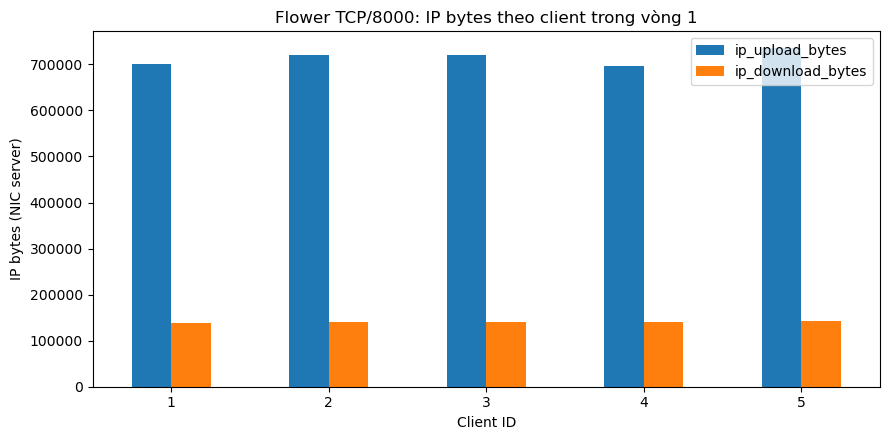

In [2]:
traffic_path = PROJECT_ROOT / "results" / "azure_traffic_new_run" / "flower_traffic_round1.json"
if traffic_path.is_file():
    traffic = json.loads(traffic_path.read_text(encoding="utf-8"))
    assert traffic["mode"] == MODE and len(traffic["clients"]) == N_CLIENTS
    traffic_rows = []
    for item in traffic["clients"]:
        traffic_rows.append({
            "client_id": item["client_id"],
            "region": "East Asia" if item["client_id"] <= 2 else "Korea Central",
            "numeric_tree_array_bytes": item["numeric_tree_array_bytes"],
            "ip_upload_bytes": item["client_to_server"]["ip_bytes"],
            "ip_download_bytes": item["server_to_client"]["ip_bytes"],
            "tcp_payload_upload_bytes": item["client_to_server"]["tcp_payload_bytes"],
            "tcp_payload_download_bytes": item["server_to_client"]["tcp_payload_bytes"],
        })
    traffic_table = pd.DataFrame(traffic_rows)
    display(traffic_table)
    print("Azure run:", traffic["run_id"], "round:", traffic["round"],
          "IP MiB total:", round(traffic["ip_mib_total"], 3),
          "seconds:", round(traffic["round_duration_seconds"], 2))
    ax = traffic_table.plot.bar(x="client_id", y=["ip_upload_bytes", "ip_download_bytes"],
                                figsize=(9, 4.5), rot=0)
    ax.set(title="Flower TCP/8000: IP bytes theo client trong vòng 1",
           xlabel="Client ID", ylabel="IP bytes (NIC server)")
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có packet report cho Azure run mới:", traffic_path)
    print("Làm theo deployment/azure/communication-cost.md rồi chạy lại ô này.")